# Анализ NASA Battery Dataset
### Оценка качества модели предсказания ёмкости аккумуляторов

**Задача:** регрессия — предсказание `capacity` по признакам `voltage`, `current`, `temperature`.

**Разбиение:**
- Train: B0005, B0006, B0007
- Test:  B0018 (Leave-One-Battery-Out)

**Что делает ноутбук:**
1. Загружает 4 `.mat` файла из текущей папки.
2. Проводит EDA: распределения, корреляции, временные ряды.
3. Обучает baseline-модель (Random Forest) на train-батареях.
4. Считает регрессионные метрики (MAE, MSE, RMSE, R², MAPE).
5. Дискретизирует ёмкость по порогам и строит confusion matrix, ROC/PR-кривые.
6. Собирает итоговые таблицы и графики.

## 1. Импорты и настройки

Импортируем всё, что нужно для загрузки `.mat`, обработки данных, обучения модели, метрик и визуализации.  
Также задаём единый стиль графиков и `random_state` для воспроизводимости.

In [4]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import loadmat

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    mean_absolute_percentage_error,
    confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve, average_precision_score,
    accuracy_score, precision_score, recall_score, f1_score
)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Библиотеки загружены.")

Библиотеки загружены.


## 2. Загрузка данных из .mat файлов

В датасете NASA Battery каждый `.mat` файл — это одна батарея.  
Внутри ключ совпадает с именем файла (`B0005`, `B0006`, ...).  
Поле `cycle` — список циклов, каждый цикл имеет `type` (`charge` / `discharge` / `impedance`).

Нас интересуют **только discharge**-циклы — там есть `Voltage_measured`, `Current_measured`, `Temperature_measured`, `Capacity`.

In [5]:
from __future__ import annotations

DATA_DIR = Path(".")  # папка, где лежат 4 .mat файла
BATTERY_FILES = ["B0005.mat", "B0006.mat", "B0007.mat", "B0018.mat"]


def load_battery(matfile: Path) -> pd.DataFrame:
    """Загружает один .mat файл и возвращает DataFrame по discharge-циклам."""
    battery_name = matfile.stem
    mat = loadmat(matfile, simplify_cells=True)

    if battery_name not in mat:
        raise KeyError(f"В {matfile.name} нет ключа '{battery_name}'")

    cycles = mat[battery_name]["cycle"]
    rows = []
    cycle_num = 0

    for cyc in cycles:
        if cyc.get("type") != "discharge":
            continue
        cycle_num += 1
        d = cyc["data"]
        rows.append({
            "battery": battery_name,
            "cycle": cycle_num,
            "voltage": float(np.mean(d["Voltage_measured"])),
            "current": float(np.mean(d["Current_measured"])),
            "temperature": float(np.mean(d["Temperature_measured"])),
            "capacity": float(d["Capacity"]),
        })

    return pd.DataFrame(rows)


def load_all_batteries(folder: Path, files: list[str]) -> pd.DataFrame:
    frames = []
    for f in files:
        p = folder / f
        if not p.exists():
            print(f"[!] Файл не найден: {p}")
            continue
        df = load_battery(p)
        print(f"{f}: {len(df)} discharge-циклов")
        frames.append(df)
    return pd.concat(frames, ignore_index=True)


df = load_all_batteries(DATA_DIR, BATTERY_FILES)
df.head()

B0005.mat: 168 discharge-циклов
B0006.mat: 168 discharge-циклов
B0007.mat: 168 discharge-циклов
B0018.mat: 132 discharge-циклов


,battery,cycle,voltage,current,temperature,capacity
0,B0005,1,3.529829,-1.818702,32.572328,1.856487
1,B0005,2,3.537320,-1.817560,32.725235,1.846327
2,B0005,3,3.543737,-1.816487,32.642862,1.835349
3,B0005,4,3.543666,-1.825589,32.514876,1.835263
4,B0005,5,3.542343,-1.826114,32.382349,1.834646


## 3. Разведочный анализ (EDA)

Смотрим:
- сколько циклов на батарею,
- как меняется ёмкость с номером цикла (деградация),
- статистики признаков,
- корреляции.

In [6]:
print("Размер датасета:", df.shape)
print("\nЦиклов на батарею:")
print(df.groupby("battery").size())

print("\nОписательные статистики:")
display(df[["voltage", "current", "temperature", "capacity"]].describe().round(4))

print("\nПропуски:")
print(df.isna().sum())

Размер датасета: (636, 6)

Циклов на батарею:
battery
B0005    168
B0006    168
B0007    168
B0018    132
dtype: int64

Описательные статистики:


,voltage,current,temperature,capacity
count,636.0000,636.0000,636.0000,636.0000
mean,3.4986,-1.8341,32.3276,1.5817
std,0.0475,0.1027,0.9711,0.1988
min,3.4039,-1.9998,30.1027,1.1538
25%,3.4667,-1.9126,31.5166,1.4211
50%,3.5025,-1.8510,32.3683,1.5597
75%,3.5411,-1.7730,33.1751,1.7635
max,3.5736,-1.5170,34.4905,2.0353



Пропуски:
battery        0
cycle          0
voltage        0
current        0
temperature    0
capacity       0
dtype: int64


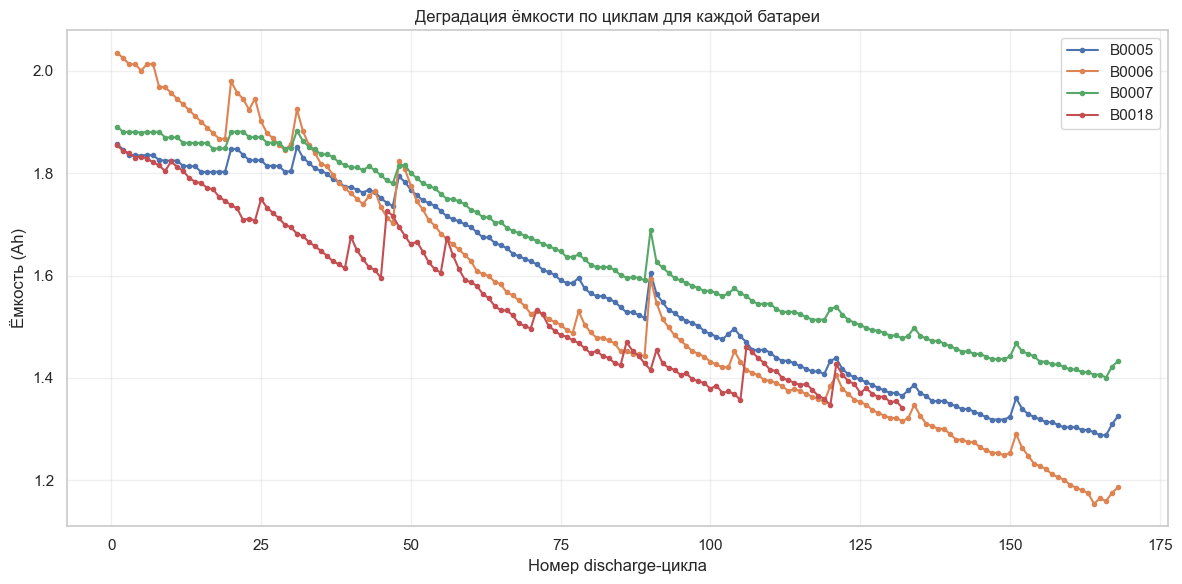

In [7]:
fig, ax = plt.subplots(figsize=(12, 6))
for b, sub in df.groupby("battery"):
    ax.plot(sub["cycle"], sub["capacity"], label=b, marker="o", markersize=3, linewidth=1.5)

ax.set_xlabel("Номер discharge-цикла")
ax.set_ylabel("Ёмкость (Ah)")
ax.set_title("Деградация ёмкости по циклам для каждой батареи")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

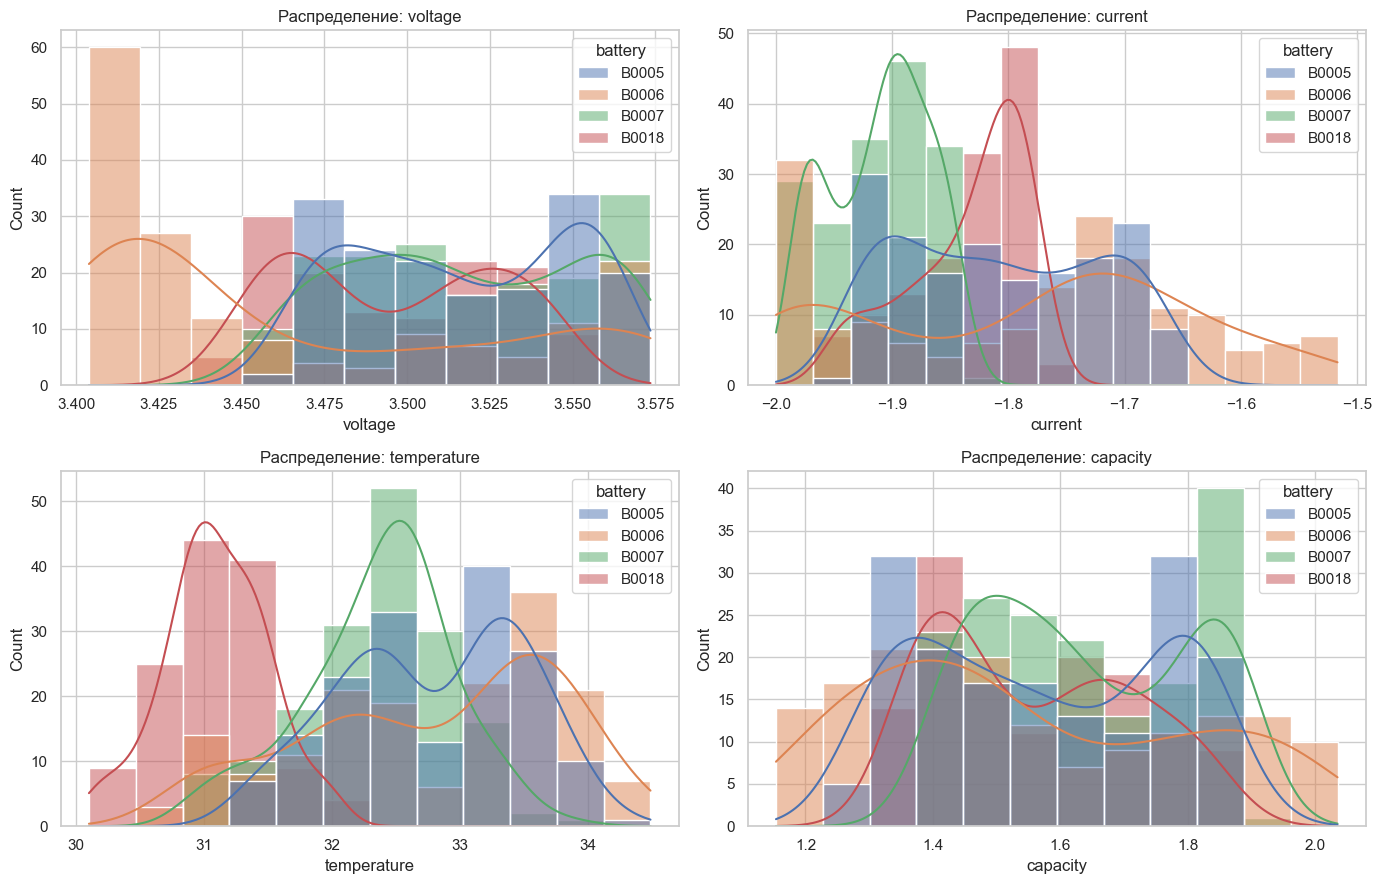

In [8]:
features = ["voltage", "current", "temperature", "capacity"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=df, x=col, hue="battery", kde=True, ax=ax, alpha=0.5)
    ax.set_title(f"Распределение: {col}")
plt.tight_layout()
plt.show()

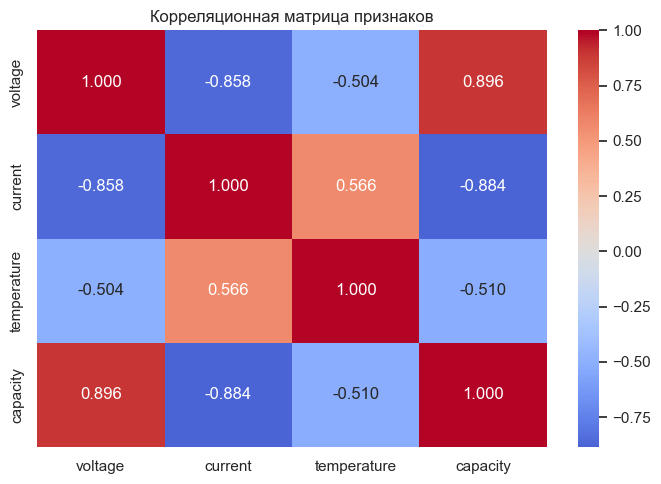

,voltage,current,temperature,capacity
voltage,1.000000,-0.857811,-0.504398,0.896274
current,-0.857811,1.000000,0.566500,-0.883573
temperature,-0.504398,0.566500,1.000000,-0.509582
capacity,0.896274,-0.883573,-0.509582,1.000000


In [9]:
corr = df[features].corr()

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Корреляционная матрица признаков")
plt.tight_layout()
plt.show()

corr

## 4. Разбиение на train/test и обучение модели

**LOBO** (Leave-One-Battery-Out): обучаем на B0005, B0006, B0007, тестируем на B0018.

Используем два baseline-а:
- **Linear Regression** — простая линейная модель,
- **Random Forest** — нелинейная модель.

По результатам выберем лучшую по RMSE на тесте.

In [10]:
TRAIN_BATTERIES = ["B0005", "B0006", "B0007"]
TEST_BATTERY = "B0018"

FEATURES = ["voltage", "current", "temperature"]
TARGET = "capacity"

train_df = df[df["battery"].isin(TRAIN_BATTERIES)].reset_index(drop=True)
test_df = df[df["battery"] == TEST_BATTERY].reset_index(drop=True)

X_train = train_df[FEATURES].values
y_train = train_df[TARGET].values
X_test = test_df[FEATURES].values
y_test = test_df[TARGET].values

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (504, 3), Test: (132, 3)


In [11]:
models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(f"{name}: обучение завершено")

LinearRegression: обучение завершено
RandomForest: обучение завершено


## 5. Регрессионные метрики

Считаем для каждой модели:
- **MAE** — средняя абсолютная ошибка
- **MSE** — средняя квадратичная ошибка
- **RMSE** — корень из MSE (в тех же единицах, что и ёмкость)
- **R²** — коэффициент детерминации (1.0 — идеал)
- **MAPE** — средняя абсолютная процентная ошибка

In [12]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE":  mean_absolute_error(y_true, y_pred),
        "MSE":  mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2":   r2_score(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred),
    }


metrics_df = pd.DataFrame({
    name: regression_metrics(y_test, pred)
    for name, pred in predictions.items()
}).T.round(4)

metrics_df

,MAE,MSE,RMSE,R2,MAPE
LinearRegression,0.0957,0.0118,0.1085,0.5058,0.0650
RandomForest,0.1466,0.0325,0.1803,-0.3648,0.1013


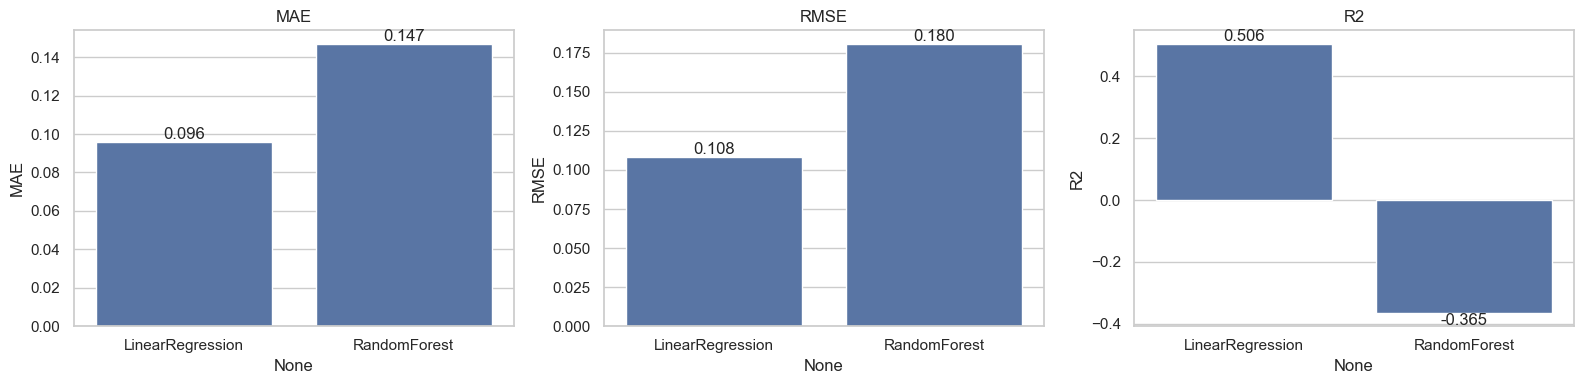

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    sns.barplot(x=metrics_df.index, y=metrics_df[metric], ax=ax)
    ax.set_title(metric)
    ax.set_ylabel(metric)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.3f")
plt.tight_layout()
plt.show()

## 6. Дискретизация ёмкости и матрица ошибок

Так как у нас регрессия, для построения **confusion matrix** переведём ёмкость в **классы состояния** по порогам:

| Класс    | Ёмкость (Ah)      | Смысл                        |
|----------|-------------------|------------------------------|
| healthy  | ≥ 1.6             | хорошее состояние            |
| medium   | 1.3 – 1.6         | умеренная деградация         |
| degraded | 1.0 – 1.3         | сильная деградация           |
| failed   | < 1.0             | вышел из строя               |

> Пороги выбраны из типичных значений NASA Battery Dataset, при необходимости их можно адаптировать.

In [14]:
CLASS_BINS = [0, 1.0, 1.3, 1.6, np.inf]
CLASS_NAMES = ["failed", "degraded", "medium", "healthy"]


def to_class(values):
    """Переводит непрерывную ёмкость в классы."""
    return pd.cut(values, bins=CLASS_BINS, labels=CLASS_NAMES, include_lowest=True)


y_test_cls = to_class(y_test).astype(str)

print("Распределение истинных классов на тесте:")
print(pd.Series(y_test_cls).value_counts())

Распределение истинных классов на тесте:
medium     75
healthy    57
Name: count, dtype: int64


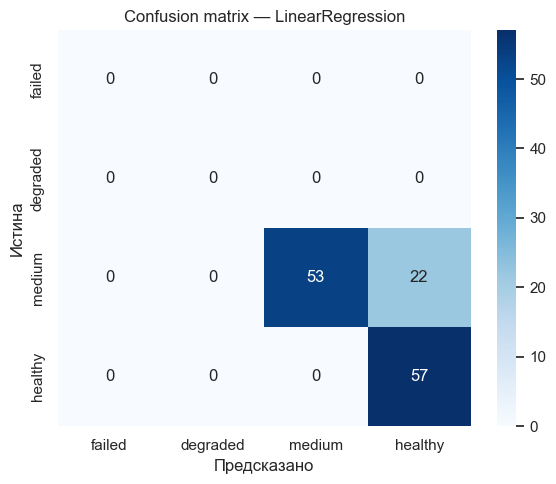


=== LinearRegression ===
              precision    recall  f1-score   support

      failed       0.00      0.00      0.00         0
    degraded       0.00      0.00      0.00         0
      medium       1.00      0.71      0.83        75
     healthy       0.72      1.00      0.84        57

   micro avg       0.83      0.83      0.83       132
   macro avg       0.43      0.43      0.42       132
weighted avg       0.88      0.83      0.83       132



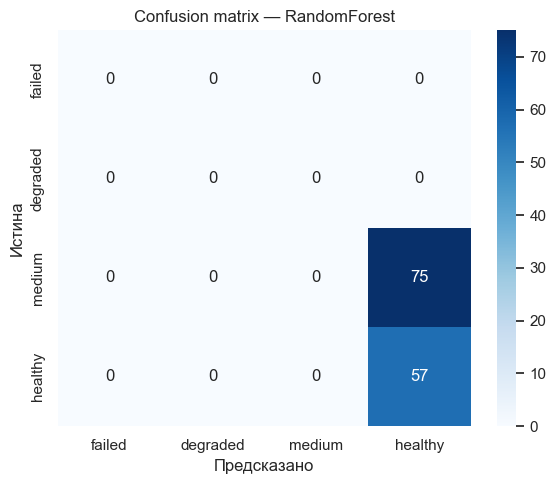


=== RandomForest ===
              precision    recall  f1-score   support

      failed       0.00      0.00      0.00         0
    degraded       0.00      0.00      0.00         0
      medium       0.00      0.00      0.00        75
     healthy       0.43      1.00      0.60        57

   micro avg       0.43      0.43      0.43       132
   macro avg       0.11      0.25      0.15       132
weighted avg       0.19      0.43      0.26       132



In [15]:
for name, pred in predictions.items():
    y_pred_cls = to_class(pred).astype(str)

    cm = confusion_matrix(y_test_cls, y_pred_cls, labels=CLASS_NAMES)

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel("Предсказано")
    ax.set_ylabel("Истина")
    ax.set_title(f"Confusion matrix — {name}")
    plt.tight_layout()
    plt.show()

    print(f"\n=== {name} ===")
    print(classification_report(y_test_cls, y_pred_cls, labels=CLASS_NAMES, zero_division=0))

## 7. Классификационные метрики (на дискретизированных классах)

Accuracy, Precision, Recall, F1 — macro-усреднение.  
Показывают, насколько модель правильно определяет **состояние** батареи.

In [16]:
rows = []
for name, pred in predictions.items():
    y_pred_cls = to_class(pred).astype(str)
    rows.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test_cls, y_pred_cls),
        "Precision (macro)": precision_score(y_test_cls, y_pred_cls, average="macro", zero_division=0),
        "Recall (macro)":    recall_score(y_test_cls, y_pred_cls, average="macro", zero_division=0),
        "F1 (macro)":        f1_score(y_test_cls, y_pred_cls, average="macro", zero_division=0),
    })

cls_metrics_df = pd.DataFrame(rows).set_index("Model").round(4)
cls_metrics_df

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
LinearRegression,0.8333,0.8608,0.8533,0.8332
RandomForest,0.4318,0.2159,0.5000,0.3016


## 8. ROC- и PR-кривые (one-vs-rest)

Строим для лучшей модели. Каждый класс — против остальных.  
По оси X — FPR, по оси Y — TPR. AUC показывает качество разделения.

In [17]:
best_model_name = metrics_df["RMSE"].idxmin()
best_model = models[best_model_name]
y_pred_best = predictions[best_model_name]

print(f"Лучшая модель по RMSE: {best_model_name}")

# Для ROC/PR нужны вероятности — берём vote-probability из деревьев RF
if hasattr(best_model, "predict_proba"):
    proba = best_model.predict_proba(X_test)
else:
    # для LinearRegression — используем softmax по отрицательному расстоянию до центра класса
    proba = None

if proba is not None:
    classes_present = list(best_model.classes_)
    # упорядочим по нашим классам
    order = [classes_present.index(c) for c in CLASS_NAMES if c in classes_present]
    proba = proba[:, order]

    y_test_bin = label_binarize(y_test_cls, classes=CLASS_NAMES)

    # ROC
    fig, ax = plt.subplots(figsize=(8, 6))
    for i, cls in enumerate(CLASS_NAMES):
        if y_test_bin[:, i].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba[:, i])
        ax.plot(fpr, tpr, label=f"{cls} (AUC={auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"ROC-кривые (OvR) — {best_model_name}")
    ax.legend()
    plt.tight_layout()
    plt.show()

    # PR
    fig, ax = plt.subplots(figsize=(8, 6))
    for i, cls in enumerate(CLASS_NAMES):
        if y_test_bin[:, i].sum() == 0:
            continue
        prec, rec, _ = precision_recall_curve(y_test_bin[:, i], proba[:, i])
        ap = average_precision_score(y_test_bin[:, i], proba[:, i])
        ax.plot(rec, prec, label=f"{cls} (AP={ap:.3f})")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title(f"Precision-Recall (OvR) — {best_model_name}")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("У выбранной модели нет predict_proba — ROC/PR пропущены.")

Лучшая модель по RMSE: LinearRegression
У выбранной модели нет predict_proba — ROC/PR пропущены.


## 9. Визуальное сравнение предсказаний

- График «истина vs предсказание» по циклам.
- Scatter «истина vs предсказание» с диагональю y=x.
- Остатки (residuals).

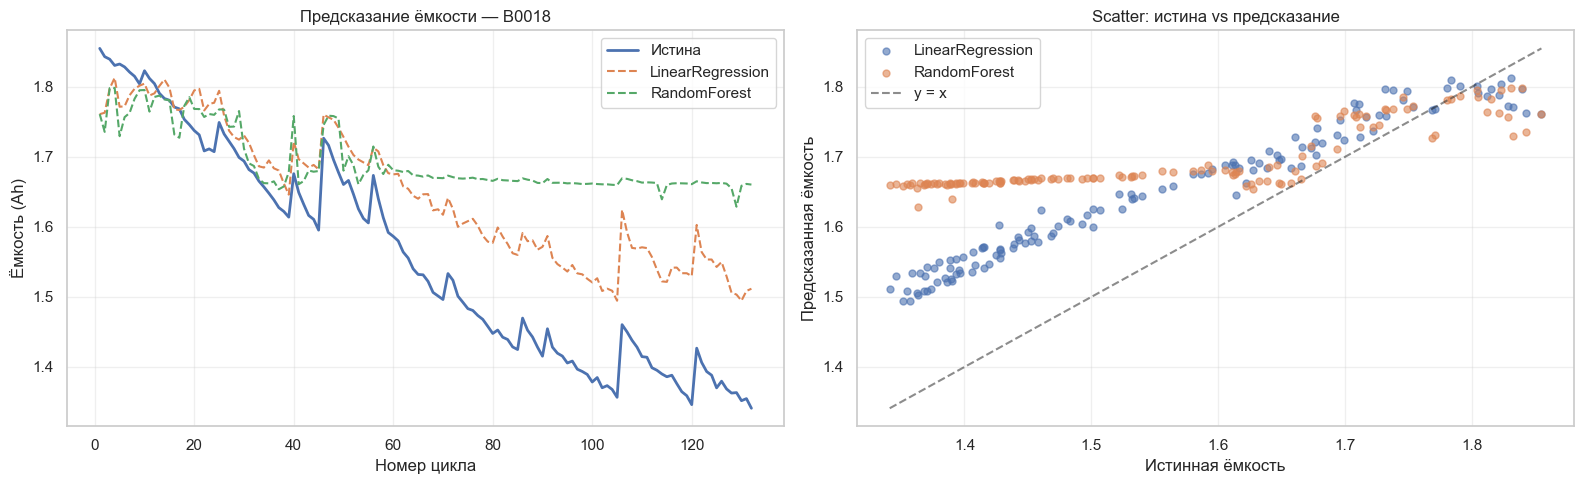

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. по циклам
ax = axes[0]
ax.plot(test_df["cycle"], y_test, label="Истина", linewidth=2)
for name, pred in predictions.items():
    ax.plot(test_df["cycle"], pred, label=f"{name}", linestyle="--", linewidth=1.5)
ax.set_xlabel("Номер цикла")
ax.set_ylabel("Ёмкость (Ah)")
ax.set_title(f"Предсказание ёмкости — {TEST_BATTERY}")
ax.legend()
ax.grid(True, alpha=0.3)

# 2. scatter
ax = axes[1]
for name, pred in predictions.items():
    ax.scatter(y_test, pred, alpha=0.6, label=name, s=25)
lims = [min(y_test.min(), min(p.min() for p in predictions.values())),
        max(y_test.max(), max(p.max() for p in predictions.values()))]
ax.plot(lims, lims, "k--", alpha=0.5, label="y = x")
ax.set_xlabel("Истинная ёмкость")
ax.set_ylabel("Предсказанная ёмкость")
ax.set_title("Scatter: истина vs предсказание")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

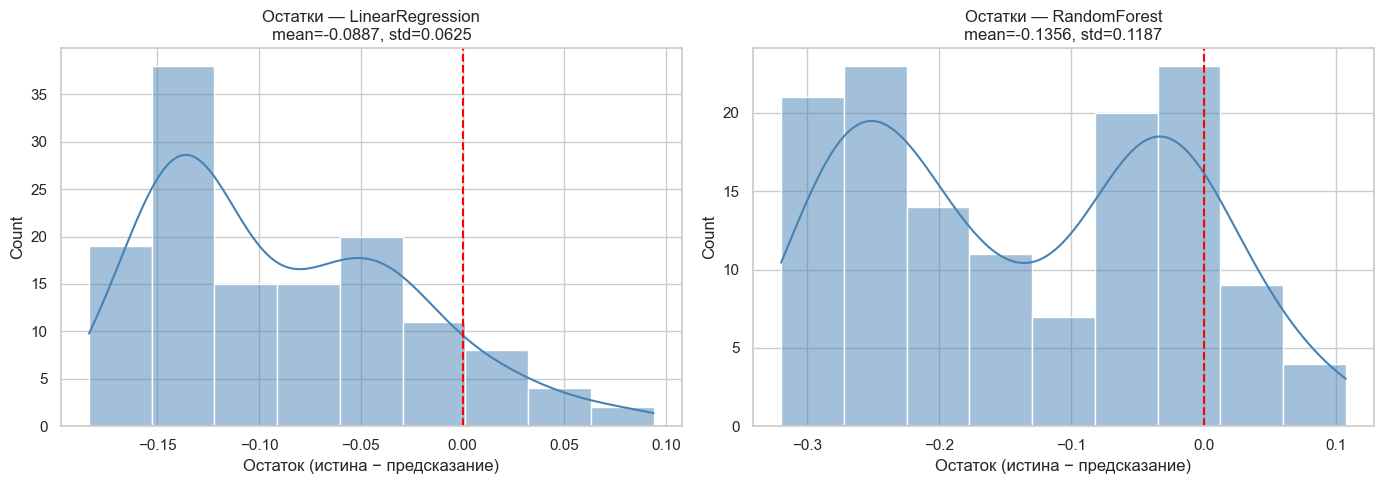

In [19]:
fig, axes = plt.subplots(1, len(predictions), figsize=(7 * len(predictions), 5))
if len(predictions) == 1:
    axes = [axes]

for ax, (name, pred) in zip(axes, predictions.items()):
    residuals = y_test - pred
    sns.histplot(residuals, kde=True, ax=ax, color="steelblue")
    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(f"Остатки — {name}\nmean={residuals.mean():.4f}, std={residuals.std():.4f}")
    ax.set_xlabel("Остаток (истина − предсказание)")

plt.tight_layout()
plt.show()

## 10. Итоговая сводная таблица

In [20]:
summary = metrics_df.join(cls_metrics_df, how="outer")
summary

,MAE,MSE,RMSE,R2,MAPE,Accuracy,Precision (macro),Recall (macro),F1 (macro)
LinearRegression,0.0957,0.0118,0.1085,0.5058,0.0650,0.8333,0.8608,0.8533,0.8332
RandomForest,0.1466,0.0325,0.1803,-0.3648,0.1013,0.4318,0.2159,0.5000,0.3016


In [21]:
out_dir = Path("results")
out_dir.mkdir(exist_ok=True)

metrics_df.to_csv(out_dir / "regression_metrics.csv", encoding="utf-8")
cls_metrics_df.to_csv(out_dir / "classification_metrics.csv", encoding="utf-8")
summary.to_csv(out_dir / "summary.csv", encoding="utf-8")

# Сохраняем предсказания
preds_df = test_df.copy()
for name, pred in predictions.items():
    preds_df[f"pred_{name}"] = pred
preds_df.to_csv(out_dir / "predictions.csv", index=False, encoding="utf-8")

print("Результаты сохранены в папку:", out_dir.resolve())

Результаты сохранены в папку: G:\Мой диск\БПА23-02\7_семестр\деятельность доррера\results
